<a href="https://colab.research.google.com/github/HatamiM12/Machine-Learning-Training/blob/main/breast_cancer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [80]:
#Import libreries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from matplotlib.colors import ListedColormap
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

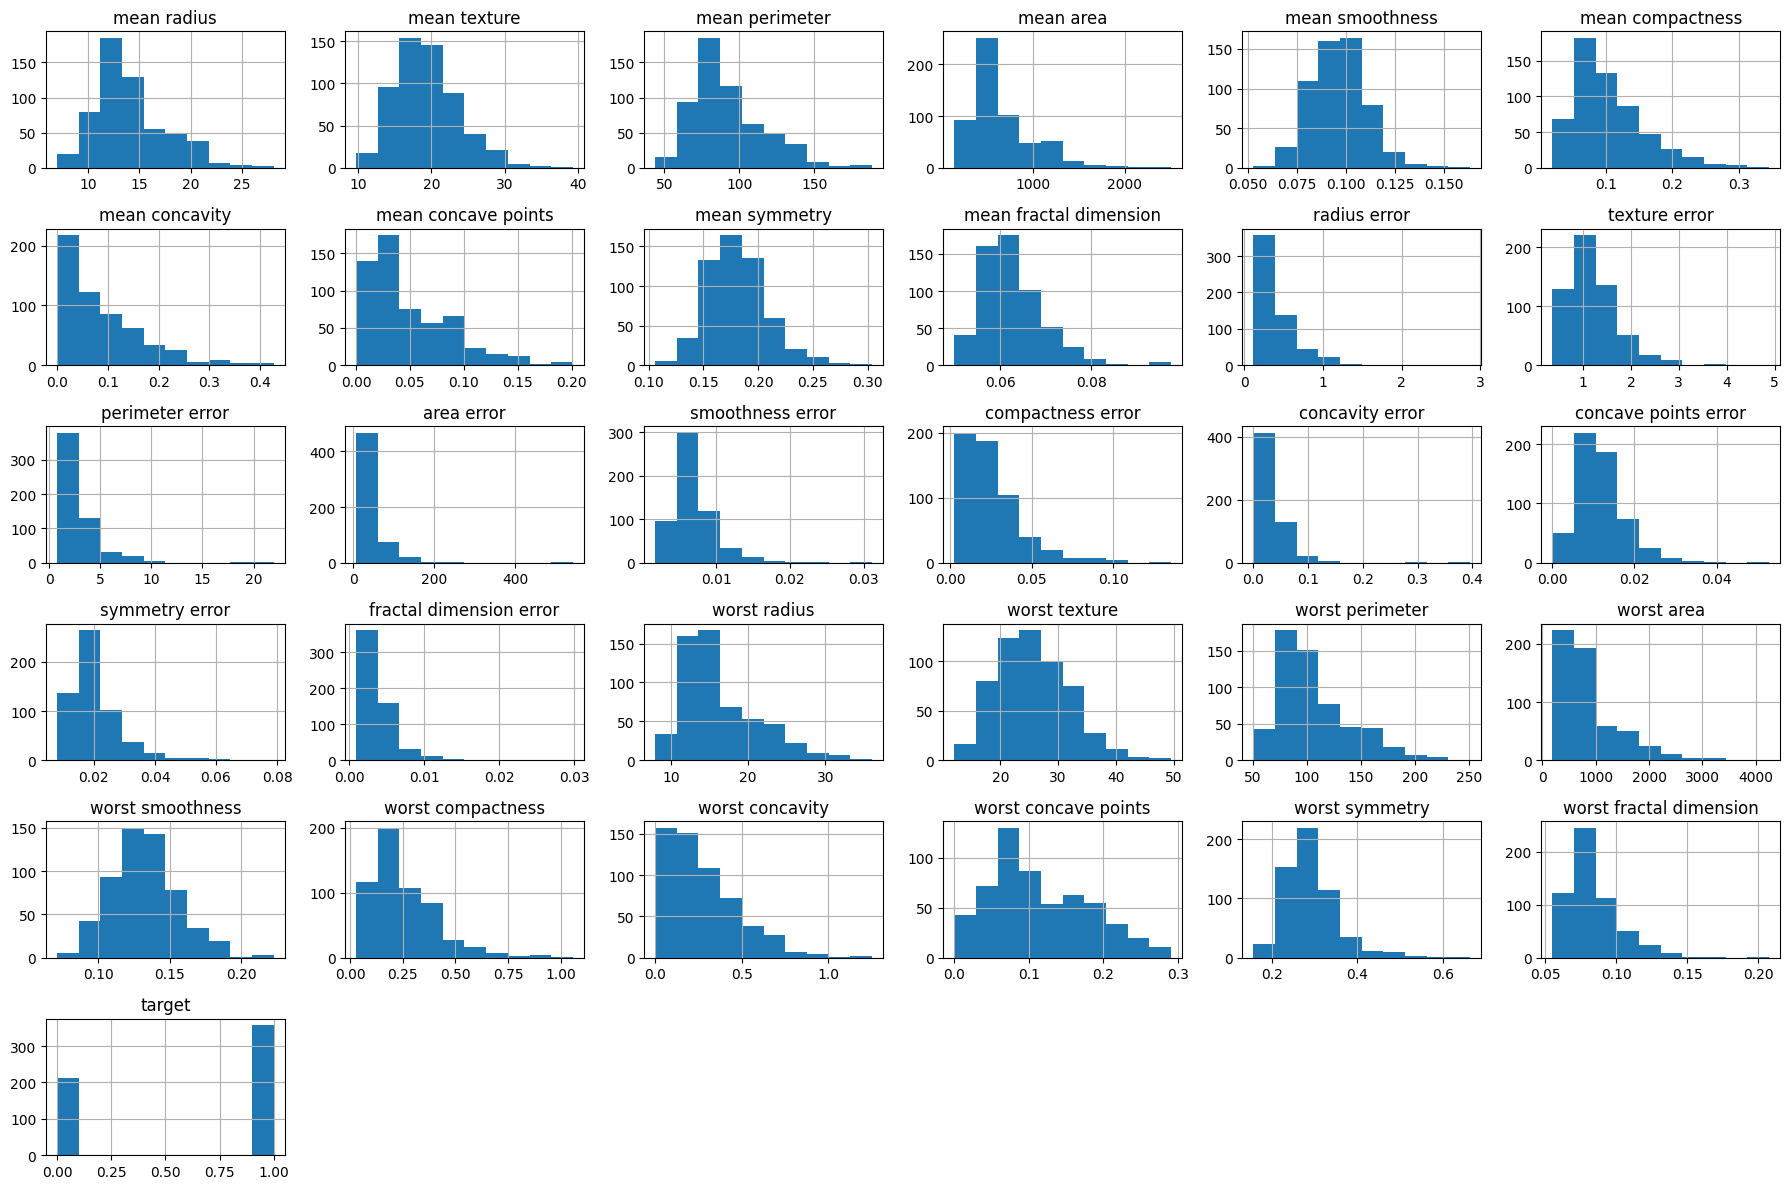

In [81]:
#Data visualization
data_frame = load_breast_cancer(as_frame=True).frame
data_frame.hist(figsize=(18, 12))
plt.tight_layout()

In [82]:
#Splitting data
data = load_breast_cancer()
X, y = data.data, data.target
feature_names = data.feature_names

df = pd.DataFrame(X, columns=data.feature_names)
df['target'] = y
selected_features = ['mean radius', 'mean texture']
X_selected = df[selected_features].values
y_selected = y

X_train, X_test, y_train, y_test = train_test_split(X_selected, y_selected , test_size=0.2, random_state=42, stratify = y_selected)


print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples: {X_test.shape[0]}")

Training samples: 455
Testing samples: 114


In [83]:
#Data Preprocessing
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

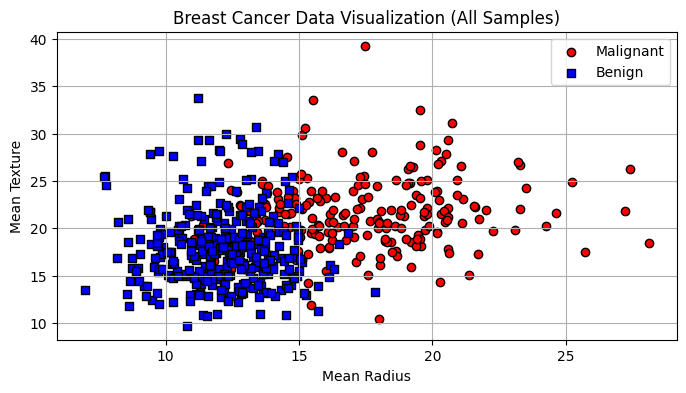

In [84]:
#Visualizing Features
plt.figure(figsize=(8, 4))
plt.scatter(X_selected[y == 0, 0], X_selected[y == 0, 1],  color='red', marker='o', edgecolor='k', label='Malignant')
plt.scatter(X_selected[y == 1, 0], X_selected[y ==1, 1], color='blue', marker='s', edgecolor='k', label='Benign')
plt.xlabel('Mean Radius')
plt.ylabel('Mean Texture')
plt.title('Breast Cancer Data Visualization (All Samples)')
plt.legend()
plt.grid(True)
plt.show()

Final Weights: [[-1.56718 -0.37   ]]
Final Bias: [29.83]


0.8879120879120879

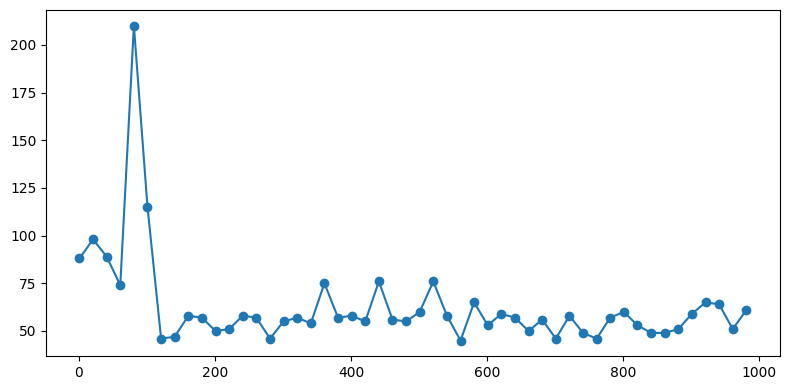

In [85]:
percept = Perceptron(eta0=0.01, random_state=42)
percept.fit(X_train, y_train)


errors_per_epoch = []
classes = np.unique(y_train)

n_epochs = 1000
for epoch in range(n_epochs):
    if epoch == 0:
        percept.partial_fit(
            X_train,
            y_train,
            classes=classes
        )
    else:
        percept.partial_fit(X_train, y_train)

    y_train_pred = percept.predict(X_train)
    errors = np.sum(y_train_pred != y_train)
    errors_per_epoch.append(errors)


plt.figure(figsize=(8, 4))

epochs_to_plot = np.arange(1, n_epochs + 1)[::20]
errors_to_plot = errors_per_epoch[::20]

plt.plot(epochs_to_plot, errors_to_plot, marker='o')
plt.tight_layout()

print(f"Final Weights: {percept.coef_}")
print(f"Final Bias: {percept.intercept_}")
percept.score(X_train, y_train)

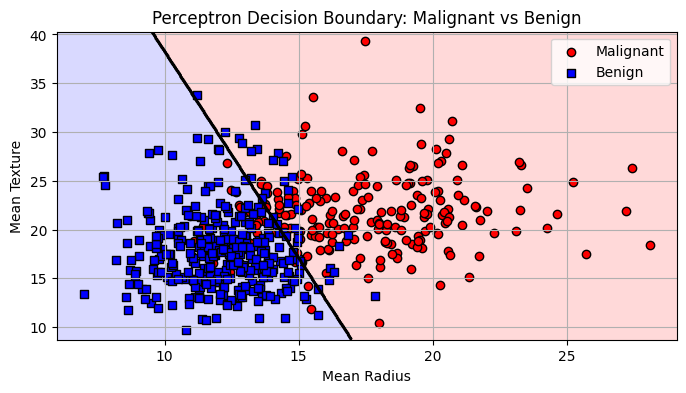

In [86]:
x_min, x_max = X_selected[:, 0].min() - 1, X_selected[:, 0].max() + 1
y_min, y_max = X_selected[:, 1].min() - 1, X_selected[:, 1].max() + 1

xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500),
                     np.linspace(y_min, y_max, 500))
grid = np.c_[xx.ravel(), yy.ravel()]
Z = percept.predict(grid).reshape(xx.shape)


plt.figure(figsize=(8, 4))
plt.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5],
             colors=['red', 'blue'], alpha=0.15)
plt.contour(xx, yy, Z, levels=[0.5], colors='black', linewidths=2)
plt.scatter(X_selected[y == 0, 0], X_selected[y == 0, 1],  color='red', marker='o', edgecolor='k', label='Malignant')
plt.scatter(X_selected[y == 1, 0], X_selected[y ==1, 1], color='blue', marker='s', edgecolor='k', label='Benign')
plt.xlabel('Mean Radius')
plt.ylabel('Mean Texture')
plt.title('Perceptron Decision Boundary: Malignant vs Benign')
plt.legend()
plt.grid(True)
plt.show()